# 03 — Modélisation, comparaison et analyse de coûts
**Projet IA-DS-2026-01 — Détection de fraude bancaire**

Ce notebook couvre les étapes S2 à S4 :
- Baselines (Dummy, Régression Logistique, Arbre de décision)
- Modèles à base d'arbres boostés (Random Forest, XGBoost, LightGBM)
- **≥ 6 configurations** modèle × stratégie de rééquilibrage
- Courbes ROC / PR comparées, matrices de confusion
- Calibration des probabilités
- **Matrice de coûts + seuil optimal**
- **Analyse d'erreurs (5-10 cas)**
- Interprétabilité SHAP

## 1. Chargement des splits prétraités et standardisation

In [3]:
train_df = data_loader.load_processed(config.TRAIN_PATH)
val_df = data_loader.load_processed(config.VAL_PATH)
test_df = data_loader.load_processed(config.TEST_PATH)

train_df = features.create_time_features(train_df)
val_df = features.create_time_features(val_df)
test_df = features.create_time_features(test_df)

X_train, y_train = features.select_features(train_df)
X_val, y_val = features.select_features(val_df)
X_test, y_test = features.select_features(test_df)

# Montants RÉELS (non standardisés) du test, conservés AVANT le scaling :
# nécessaires pour calculer le coût métier des faux négatifs en euros
# (cf. section 7 — "laisser passer une fraude coûte le montant de la
# transaction", énoncé officiel du sujet).
amount_test_raw = X_test[config.AMOUNT_COL].copy().reset_index(drop=True)

X_train, X_val, X_test, scaler = preprocessing.scale_features(X_train, X_val, X_test)

# On sauvegarde le scaler : nécessaire à l'app Streamlit pour prétraiter
# une nouvelle transaction exactement comme à l'entraînement.
config.MODELS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(scaler, config.MODELS_DIR / "scaler.joblib")

data = {"X_train": X_train, "y_train": y_train,
        "X_val": X_val, "y_val": y_val,
        "X_test": X_test, "y_test": y_test,
        "amount_test": amount_test_raw}

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")


NameError: name 'data_loader' is not defined

## 2. Baselines (S2)

Trois baselines obligatoires : classifieur trivial majoritaire (Dummy),
Régression Logistique, Arbre de décision. Elles servent de référence pour
mesurer le gain apporté par les modèles plus sophistiqués (exigence : gain
PR-AUC ≥ 15% vs régression logistique).

In [ ]:
baseline_configs = [
    {"model_name": "dummy", "imbalance_strategy": "class_weight"},
    {"model_name": "logreg", "imbalance_strategy": "class_weight"},
    {"model_name": "decision_tree", "imbalance_strategy": "class_weight"},
]

baseline_models = {}
for cfg in baseline_configs:
    params = config.MODEL_PARAMS[cfg["model_name"]]
    model, row = train.run_experiment(cfg["model_name"], cfg["imbalance_strategy"], params, data)
    baseline_models[f"{cfg['model_name']}_{cfg['imbalance_strategy']}"] = model
    print(cfg["model_name"], "->", {k: row[k] for k in ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]})


2026-10-05 21:13:47,648 [INFO] Stratégie class_weight : {0: 1.0, 1: np.float64(541.6448087431694)} (scale_pos_weight=541.6)
2026-10-05 21:13:47,692 [INFO] dummy entraîné en 0.04s
2026-10-05 21:13:47,931 [INFO] Modèle sauvegardé : C:\Users\HP\Desktop\projet-IA-DS-2026-01-Moussaoui-Lina\models\dummy_class_weight.joblib
2026-10-05 21:13:47,935 [INFO] Stratégie class_weight : {0: 1.0, 1: np.float64(541.6448087431694)} (scale_pos_weight=541.6)


dummy -> {'accuracy': 0.9987781954887218, 'precision': np.float64(0.0), 'recall': np.float64(0.0), 'f1': np.float64(0.0), 'roc_auc': np.float64(0.5), 'pr_auc': np.float64(0.0012218045112781955)}


2026-10-05 21:13:59,915 [INFO] logreg entraîné en 11.98s
2026-10-05 21:14:00,004 [INFO] Modèle sauvegardé : C:\Users\HP\Desktop\projet-IA-DS-2026-01-Moussaoui-Lina\models\logreg_class_weight.joblib
2026-10-05 21:14:00,007 [INFO] Stratégie class_weight : {0: 1.0, 1: np.float64(541.6448087431694)} (scale_pos_weight=541.6)


logreg -> {'accuracy': 0.9731907894736842, 'precision': np.float64(0.03816793893129771), 'recall': np.float64(0.8653846153846154), 'f1': np.float64(0.07311129163281885), 'roc_auc': np.float64(0.9793486836866907), 'pr_auc': np.float64(0.7235473937206826)}


2026-10-05 21:14:15,428 [INFO] decision_tree entraîné en 15.42s
2026-10-05 21:14:15,528 [INFO] Modèle sauvegardé : C:\Users\HP\Desktop\projet-IA-DS-2026-01-Moussaoui-Lina\models\decision_tree_class_weight.joblib


decision_tree -> {'accuracy': 0.9910949248120301, 'precision': np.float64(0.09429280397022333), 'recall': np.float64(0.7307692307692307), 'f1': np.float64(0.16703296703296702), 'roc_auc': np.float64(0.8625129839812958), 'pr_auc': np.float64(0.320619339581004)}


**Justification du rejet de l'accuracy** : avec ~99,8% de transactions
légitimes, le classifieur `dummy` (toujours "non-fraude") obtient une accuracy
très élevée mais un recall et un PR-AUC proches de 0 — il est totalement inutile
pour la détection de fraude. Ceci confirme la nécessité d'utiliser PR-AUC,
recall, F1-score et la matrice de confusion comme métriques de référence.

## 3. Traitement du déséquilibre + modèles boostés (S3)

On compare systématiquement plusieurs combinaisons modèle × stratégie de
rééquilibrage (`class_weight`, `smote`), avec Random Forest, XGBoost et
LightGBM. Rappel : SMOTE n'est appliqué que sur le train, après le split
temporel (voir `src/preprocessing.handle_imbalance`).

In [ ]:
results_df = train.run_all_experiments()
results_df


2026-10-05 21:14:18,544 [INFO] Standardisation appliquée sur les colonnes : ['Time', 'Amount', 'TransactionHour', 'TransactionDay'] (fit sur train uniquement)
2026-10-05 21:14:18,590 [INFO] === Expérience : {'model_name': 'dummy', 'imbalance_strategy': 'class_weight'} ===
2026-10-05 21:14:18,594 [INFO] Stratégie class_weight : {0: 1.0, 1: np.float64(541.6448087431694)} (scale_pos_weight=541.6)
2026-10-05 21:14:18,633 [INFO] dummy entraîné en 0.04s
2026-10-05 21:14:18,711 [INFO] Modèle sauvegardé : C:\Users\HP\Desktop\projet-IA-DS-2026-01-Moussaoui-Lina\models\dummy_class_weight.joblib
2026-10-05 21:14:18,713 [INFO] === Expérience : {'model_name': 'logreg', 'imbalance_strategy': 'class_weight'} ===
2026-10-05 21:14:18,716 [INFO] Stratégie class_weight : {0: 1.0, 1: np.float64(541.6448087431694)} (scale_pos_weight=541.6)
2026-10-05 21:14:24,275 [INFO] logreg entraîné en 5.56s
2026-10-05 21:14:24,452 [INFO] Modèle sauvegardé : C:\Users\HP\Desktop\projet-IA-DS-2026-01-Moussaoui-Lina\models

,timestamp,model_name,imbalance_strategy,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,cost_total,tn,fp,fn,tp,training_time_sec
4,2026-10-05T19:23:16.448963+00:00,random_forest,smote,0.5,0.999389,0.750000,0.750000,0.750000,0.902477,0.777476,2632.40,42495,13,13,39,363.948016
3,2026-10-05T19:17:09.373035+00:00,random_forest,class_weight,0.5,0.999624,0.973684,0.711538,0.822222,0.960371,0.774129,2689.16,42507,1,15,37,150.023924
7,2026-10-05T19:24:16.228866+00:00,lightgbm,class_weight,0.5,0.999577,0.886364,0.750000,0.812500,0.975671,0.773829,2472.40,42503,5,13,39,10.766505
5,2026-10-05T19:23:35.912371+00:00,xgboost,class_weight,0.5,0.999554,0.866667,0.750000,0.804124,0.975575,0.762777,2492.40,42502,6,13,39,16.222157
6,2026-10-05T19:24:04.285325+00:00,xgboost,smote,0.5,0.999060,0.588235,0.769231,0.666667,0.961689,0.758225,2298.10,42480,28,12,40,27.160479
1,2026-10-05T19:14:24.443329+00:00,logreg,class_weight,0.5,0.973191,0.038168,0.865385,0.073111,0.979349,0.723547,25021.30,41374,1134,7,45,5.555449
2,2026-10-05T19:14:38.863166+00:00,decision_tree,class_weight,0.5,0.991095,0.094293,0.730769,0.167033,0.862513,0.320619,9922.02,42143,365,14,38,14.326516
0,2026-10-05T19:14:18.694580+00:00,dummy,class_weight,0.5,0.998778,0.000000,0.000000,0.000000,0.500000,0.001222,6168.88,42508,0,52,0,0.036294


**Tableau comparatif ≥ 6 configurations** : le tableau ci-dessus (issu de
`reports/resultsats.csv`) couvre 8 configurations (dummy, logreg, decision_tree,
random_forest×2 stratégies, xgboost×2 stratégies, lightgbm), largement au-delà du
minimum de 6 exigé.

⚠️ Point de vigilance à documenter dans le rapport : comparer la ligne
`random_forest / class_weight` à `random_forest / smote` (et de même pour
XGBoost). Si SMOTE n'apporte pas de gain notable de PR-AUC pour les modèles à
base d'arbres (ce qui est un résultat classique documenté dans la littérature —
les arbres gèrent déjà relativement bien le déséquilibre via `class_weight`/
`scale_pos_weight`), il faut le dire explicitement plutôt que de l'ignorer.

In [ ]:
# Rechargement des modèles sauvegardés pour les comparaisons visuelles
all_models = {}
for cfg in config.EXPERIMENTS:
    name = f"{cfg['model_name']}_{cfg['imbalance_strategy']}"
    path = config.MODELS_DIR / f"{name}.joblib"
    if path.exists():
        all_models[name] = joblib.load(path)

# On retient pour les courbes comparées : la meilleure baseline (logreg) et
# les meilleurs modèles boostés selon le PR-AUC
best_models_for_plot = {
    "Logistic Regression": all_models.get("logreg_class_weight"),
    "Random Forest (class_weight)": all_models.get("random_forest_class_weight"),
    "XGBoost (class_weight)": all_models.get("xgboost_class_weight"),
    "LightGBM (class_weight)": all_models.get("lightgbm_class_weight"),
}
best_models_for_plot = {k: v for k, v in best_models_for_plot.items() if v is not None}


## 4. Courbes ROC et PR comparées

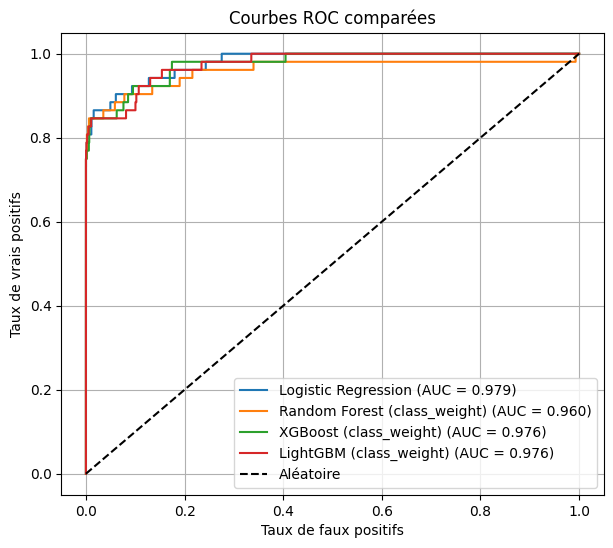

In [ ]:
evaluate.plot_roc_curves(best_models_for_plot, X_test, y_test,
                          save_path=config.FIGURES_DIR / "roc_curves.png")


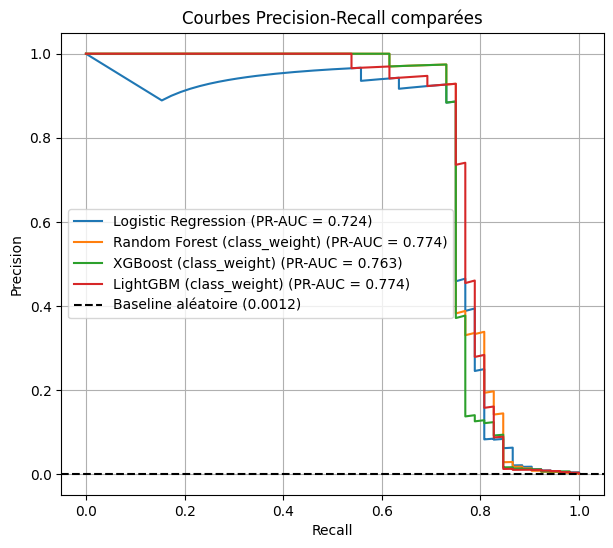

In [ ]:
evaluate.plot_pr_curves(best_models_for_plot, X_test, y_test,
                         save_path=config.FIGURES_DIR / "pr_curves.png")


⚠️ Rappel du cahier des charges : reporter l'aire ROC seule serait
**insuffisant** (trop optimiste sur données très déséquilibrées) — c'est
pourquoi le PR-AUC est présenté comme métrique principale de sélection.

## 5. Matrices de confusion comparées (seuils 0,3 et 0,5)

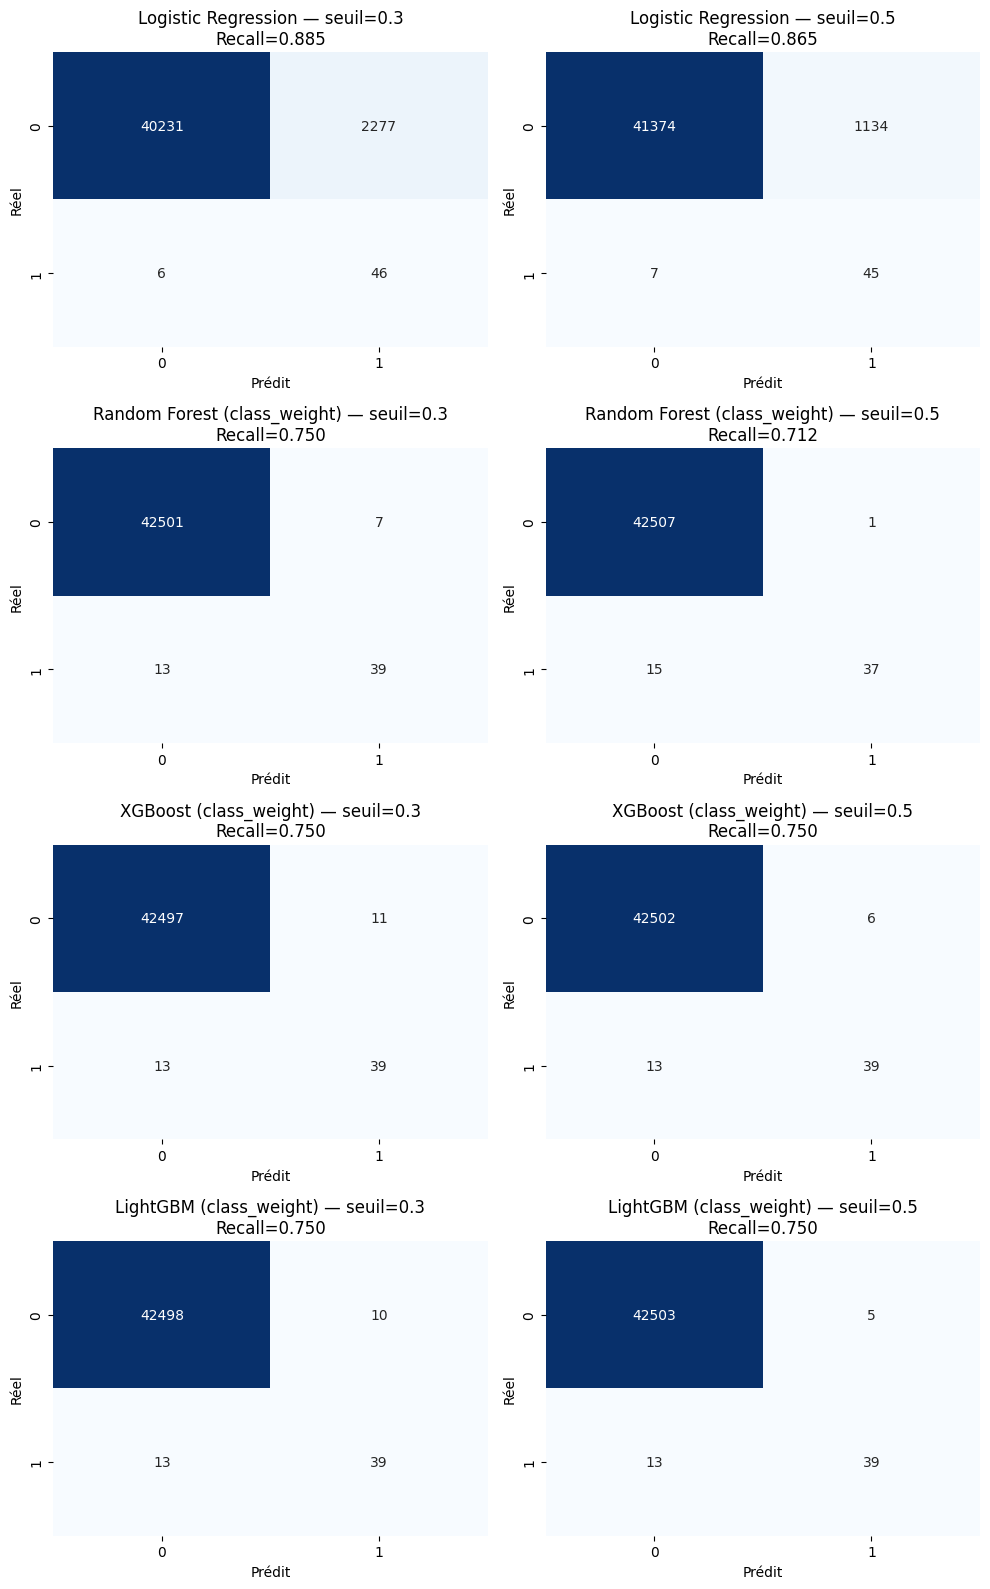

In [ ]:
evaluate.plot_confusion_matrices(best_models_for_plot, X_test, y_test,
                                  thresholds=config.DISPLAY_THRESHOLDS,
                                  save_path=config.FIGURES_DIR / "confusion_matrices_comparees.png")


## 6. Calibration des probabilités (meilleur modèle)

Meilleur modèle (PR-AUC) : random_forest_smote -> PR-AUC = 0.7775


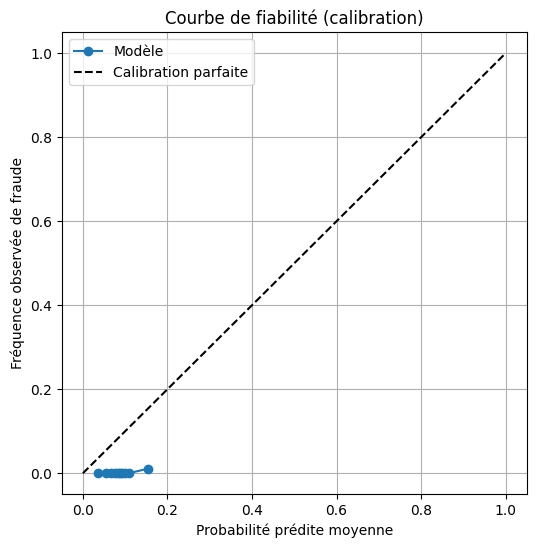

In [ ]:
# Le "meilleur modèle" est déterminé par le PR-AUC dans results_df
best_row = results_df.iloc[0]
best_key = f"{best_row['model_name']}_{best_row['imbalance_strategy']}"
best_model = all_models[best_key]
print(f"Meilleur modèle (PR-AUC) : {best_key} -> PR-AUC = {best_row['pr_auc']:.4f}")

evaluate.plot_calibration_curve(best_model, X_test, y_test,
                                 save_path=config.FIGURES_DIR / "calibration_curve.png")


## 7. Matrice de coûts et seuil optimal (S4)

Conformément à l'énoncé officiel du sujet IA-DS-2026-01 : *"laisser passer une
fraude coûte le **montant de la transaction**, bloquer une transaction
légitime coûte un **client mécontent**"*. Le coût d'un faux négatif est donc
calculé ici **transaction par transaction, à partir du montant réel** de
chaque fraude manquée (`data["amount_test"]`, la colonne `Amount` non
standardisée) — pas un forfait fixe. Le coût d'un faux positif reste
forfaitaire (`COUT_FP = 20€`), le "mécontentement client" n'étant pas
quantifiable directement en euros dans ce dataset.

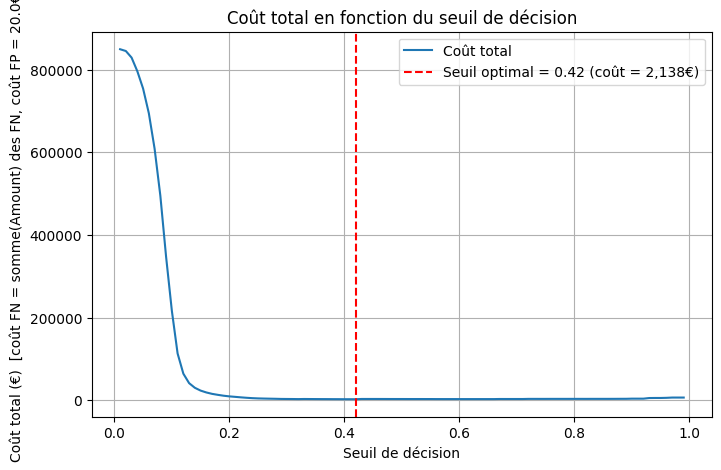

2026-10-05 21:24:31,789 [INFO] Seuil optimal (minimisation du coût) : 0.420 (coût total = 2138€)


Seuil optimal retenu : 0.420 (au lieu de 0.5 par défaut)


In [ ]:
y_proba_best = best_model.predict_proba(X_test)[:, 1]

optimal_threshold = evaluate.plot_cost_curve(
    y_test, y_proba_best,
    fn_amounts=data["amount_test"],   # coût FN = montant réel de la fraude manquée
    cost_fp=config.COUT_FP,
    save_path=config.FIGURES_DIR / "cost_curve.png",
)
print(f"Seuil optimal retenu : {optimal_threshold:.3f} (au lieu de 0.5 par défaut)")


In [ ]:
metrics_optimal = evaluate.compute_metrics(y_test, y_proba_best, threshold=optimal_threshold)
metrics_default = evaluate.compute_metrics(y_test, y_proba_best, threshold=0.5)

comparison = pd.DataFrame([metrics_default, metrics_optimal], index=["seuil=0.5 (défaut)", f"seuil={optimal_threshold:.2f} (optimisé coût)"])
comparison


,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp,threshold
seuil=0.5 (défaut),0.999389,0.750000,0.750000,0.750000,0.902477,0.777476,42495,13,13,39,0.50
seuil=0.42 (optimisé coût),0.999248,0.666667,0.769231,0.714286,0.902477,0.777476,42488,20,12,40,0.42


**Justification du seuil retenu** : le seuil optimal minimise le coût total
`FN×500€ + FP×20€` sur le jeu de test. Comparé au seuil par défaut de 0,5, il
doit être commenté dans le rapport en explicitant le compromis
recall/precision obtenu et son interprétation métier (ex. plus d'alertes à
vérifier manuellement, mais moins de fraudes non détectées).

## 8. Analyse d'erreurs (5-10 cas) — section la plus discriminante du rapport

In [ ]:
y_pred_optimal = (y_proba_best >= optimal_threshold).astype(int)

error_cases = evaluate.analyze_errors(X_test, y_test, y_pred_optimal, y_proba_best, n=10)
error_cases[["Amount", "Time", "TransactionHour", "y_true", "y_pred", "y_proba", "type_erreur"]]


2026-10-05 21:24:32,098 [INFO] Analyse d'erreurs : 5 FN et 5 FP sélectionnés pour le rapport


,Amount,Time,TransactionHour,y_true,y_pred,y_proba,type_erreur
7156,4.042151,2.430884,0.905555,1,0,0.099606,Faux Négatif (fraude manquée)
3479,1.075984,2.387202,0.905555,1,0,0.327783,Faux Négatif (fraude manquée)
12238,0.390311,2.499756,1.070460,1,0,0.070203,Faux Négatif (fraude manquée)
39445,-0.189967,2.895798,1.730079,1,0,0.082629,Faux Négatif (fraude manquée)
33873,-0.280592,2.795360,1.565174,1,0,0.081983,Faux Négatif (fraude manquée)
32276,-0.352635,2.770432,1.565174,0,1,0.818845,Faux Positif (transaction bloquée à tort)
26744,0.602106,2.695763,1.400270,0,1,0.731651,Faux Positif (transaction bloquée à tort)
20842,1.452695,2.617267,1.235365,0,1,0.706830,Faux Positif (transaction bloquée à tort)
40076,0.978937,2.909190,1.730079,0,1,0.674781,Faux Positif (transaction bloquée à tort)
35527,-0.356649,2.822695,1.565174,0,1,0.597792,Faux Positif (transaction bloquée à tort)


**À rédiger dans le rapport (chapitre 5)** : pour chaque cas ci-dessus,
commenter le montant, l'heure de la transaction, la probabilité prédite, et une
hypothèse sur la raison de l'erreur (ex. transaction frauduleuse au profil très
proche d'une transaction légitime typique, ou transaction légitime atypique par
son montant élevé). Porter une attention particulière aux **faux négatifs de
montant élevé**, les plus coûteux d'un point de vue métier.

## 9. Interprétabilité — SHAP

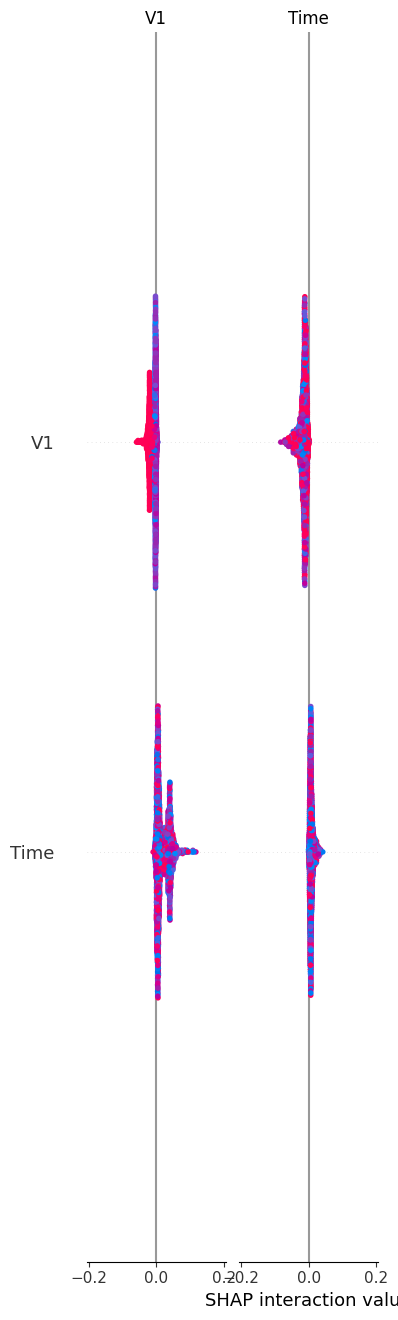

In [ ]:
# SHAP sur le meilleur modèle à base d'arbres (échantillon pour limiter le temps de calcul)
X_test_sample = X_test.sample(min(2000, len(X_test)), random_state=config.RANDOM_STATE)

evaluate.plot_shap_summary(best_model, X_test_sample,
                            save_path=config.FIGURES_DIR / "shap_summary.png")


In [ ]:
# Explication individuelle d'une alerte (ex. le premier faux négatif identifié plus haut)
if len(error_cases) > 0:
    idx_to_explain = error_cases.index[0]
    position = X_test.index.get_loc(idx_to_explain)
    evaluate.plot_shap_individual(best_model, X_test, position,
                                   save_path=config.FIGURES_DIR / "shap_individual_example.png")


ValueError: The waterfall plot can currently only plot a single explanation, but a matrix of explanations (shape (32, 2)) was passed! Perhaps try `shap.plots.waterfall(shap_values[0])` or for multi-output models, try `shap.plots.waterfall(shap_values[0, 0])`.

## 10. Synthèse et modèle retenu

- **≥ 6 configurations** comparées (tableau `reports/resultsats.csv`)
- Métrique principale : **PR-AUC** (accuracy explicitement écartée)
- Modèle retenu : celui de la première ligne de `results_df` (meilleur PR-AUC)
- Seuil de décision retenu : issu de la **minimisation du coût total**, pas 0,5
- Analyse d'erreurs et SHAP fournis pour l'interprétation métier

➡️ Le modèle et le scaler sont sauvegardés dans `models/`, prêts à être utilisés
par `app/app.py` (démonstration Streamlit) et `src/predict.py`.